In [1]:
import pandas
import numpy
import matplotlib
import sklearn
import requests

print(pandas.__version__)
print(numpy.__version__)
print(matplotlib.__version__)
print(sklearn.__version__)
print(requests.__version__)

3.1.1
2.5.4
3.11.2
1.9.1
2.34.2


#My notes

Place: Mafikeng, latitude about -25.86, longitude about 25.64
Start: 2020-11-12
End: 2026-11-02
Variables: 
temperature_2m_max
temperature_2m_min
precipitation_sum
wind_speed_10m_max
Target: temperature_2m_max for tommorrow (regresssion)
Checks passed: 2182 rows, no gaps, no duplicates, no nulls, min < max on everyday

In [2]:
the_link = "https://archive-api.open-meteo.com/v1/archive"
the_dic = {"latitude": "-25.86", "longitude": "25.64", "start_date": "2020-11-12", "end_date": "2026-11-02", "timezone": "Africa/Johannesburg", "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max"}

In [3]:
response= requests.get(the_link, params=the_dic)
print(response.status_code)

200


In [6]:
data = response.json()
print(data.keys())
print(data["daily_units"])
print(data["daily"].keys())
print(len(data["daily"]["time"]))
print(data["latitude"])
print(data["longitude"])


dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily'])
{'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'km/h'}
dict_keys(['time', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'wind_speed_10m_max'])
2182
-25.834799
25.616138


In [7]:
df = pandas.DataFrame(data["daily"])
print(df.head())
df["time"] = pandas.to_datetime(df["time"])
df.to_csv("../data/raw/mahikeng_daily_raw.csv", index=False)
df.info()
print(df.isna().sum())

         time  temperature_2m_max  temperature_2m_min  precipitation_sum  \
0  2020-11-12                25.2                16.5                0.1   
1  2020-11-13                25.9                14.6                0.0   
2  2020-11-14                28.0                14.0                0.6   
3  2020-11-15                30.9                14.1                0.0   
4  2020-11-16                31.0                17.2                0.0   

   wind_speed_10m_max  
0                28.6  
1                18.5  
2                20.5  
3                16.5  
4                18.1  
<class 'pandas.DataFrame'>
RangeIndex: 2182 entries, 0 to 2181
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   time                2182 non-null   datetime64[us]
 1   temperature_2m_max  2182 non-null   float64       
 2   temperature_2m_min  2182 non-null   float64       
 3   precipitation_sum  

                      time  temperature_2m_max  temperature_2m_min  \
count                 2182         2182.000000         2182.000000   
mean   2023-11-07 12:00:00           26.021769           12.290009   
min    2020-11-12 00:00:00            9.500000           -3.300000   
25%    2022-05-11 06:00:00           22.300000            8.300000   
50%    2023-11-07 12:00:00           26.300000           13.400000   
75%    2025-05-05 18:00:00           29.600000           16.700000   
max    2026-11-02 00:00:00           37.900000           23.300000   
std                    NaN            4.947162            5.306486   

       precipitation_sum  wind_speed_10m_max  
count        2182.000000         2182.000000  
mean            1.473648           18.572411  
min             0.000000            6.200000  
25%             0.000000           14.400000  
50%             0.000000           17.800000  
75%             0.400000           22.000000  
max            66.600000           46.90

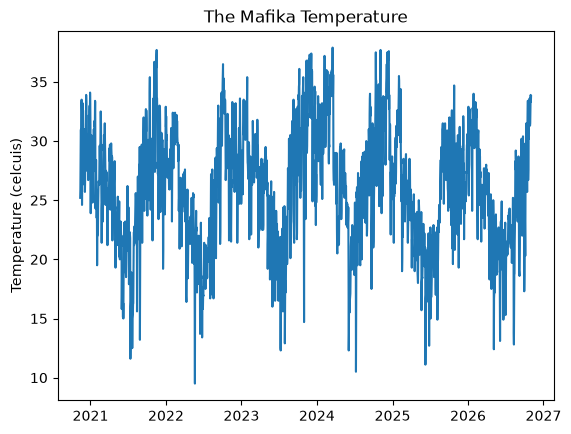

In [ ]:
df2 = pandas.read_csv("../data/raw/mahikeng_daily_raw.csv", parse_dates = ["time"])

#Reads the minimum and max rows if they make sense
print(df2.describe())

#No date appears twice || more
print(df2["time"].is_unique)

#counting the gaps between consecutive dates
print(df2["time"].diff().value_counts())
import matplotlib.pyplot as plt
plt.plot(df2["time"], df2["temperature_2m_max"])
plt.title("The Mafika Temperature")
plt.ylabel("Temperature (celcuis)")
plt.show()


In [ ]:
#Checking whether if the data makes sense must print 0, meaning never since 2020 the minimum temp was > than max temp
print((df2["temperature_2m_min"] > df2["temperature_2m_max"]).sum())

0


In [ ]:
#Creating a column and with tomorrow's max
df2["target_tomorrow_max"] = df2["temperature_2m_max"].shift(-1)
print(df2.head(4))
print(df2.tail(3))

        time  temperature_2m_max  temperature_2m_min  precipitation_sum  \
0 2020-11-12                25.2                16.5                0.1   
1 2020-11-13                25.9                14.6                0.0   
2 2020-11-14                28.0                14.0                0.6   
3 2020-11-15                30.9                14.1                0.0   

   wind_speed_10m_max  target_tomorrow_max  
0                28.6                 25.9  
1                18.5                 28.0  
2                20.5                 30.9  
3                16.5                 31.0  
           time  temperature_2m_max  temperature_2m_min  precipitation_sum  \
2179 2026-10-31                33.9                18.9                0.0   
2180 2026-11-01                33.3                19.6                1.1   
2181 2026-11-02                33.8                16.5                0.5   

      wind_speed_10m_max  target_tomorrow_max  
2179                17.7              

In [ ]:
#checking yesterday's max temp
df2["max_lag1"] = df2["temperature_2m_max"].shift(1)

#checking 2 days ago of temp max
df2["max_lag2"] = df2["temperature_2m_max"].shift(2)
print(df2.head(4))

        time  temperature_2m_max  temperature_2m_min  precipitation_sum  \
0 2020-11-12                25.2                16.5                0.1   
1 2020-11-13                25.9                14.6                0.0   
2 2020-11-14                28.0                14.0                0.6   
3 2020-11-15                30.9                14.1                0.0   

   wind_speed_10m_max  target_tomorrow_max  max_lag1  max_lag2  
0                28.6                 25.9       NaN       NaN  
1                18.5                 28.0      25.2       NaN  
2                20.5                 30.9      25.9      25.2  
3                16.5                 31.0      28.0      25.9  


In [14]:
for lag in [1, 2, 3, 4, 5, 6, 7]:
    df2[f"max_lag{lag}"] = df2["temperature_2m_max"].shift(lag)
for lag2 in [1, 2, 3]:
    df2[f"min_lag{lag2}"] = df2["temperature_2m_min"].shift(lag2)
    df2[f"sum_of_precipitation{lag2}"] = df2["precipitation_sum"].shift(lag2)
    df2[f"max_lag_wind{lag2}"] = df2["wind_speed_10m_max"].shift(lag2)

print(df2.columns)
print(df2.head(8))

Index(['time', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum',
       'wind_speed_10m_max', 'target_tomorrow_max', 'max_lag1', 'max_lag2',
       'max_lag3', 'max_lag4', 'max_lag5', 'max_lag6', 'max_lag7', 'min_lag1',
       'sum_of_precipitation1', 'max_lag_wind1', 'min_lag2',
       'sum_of_precipitation2', 'max_lag_wind2', 'min_lag3',
       'sum_of_precipitation3', 'max_lag_wind3'],
      dtype='str')
        time  temperature_2m_max  temperature_2m_min  precipitation_sum  \
0 2020-11-12                25.2                16.5                0.1   
1 2020-11-13                25.9                14.6                0.0   
2 2020-11-14                28.0                14.0                0.6   
3 2020-11-15                30.9                14.1                0.0   
4 2020-11-16                31.0                17.2                0.0   
5 2020-11-17                29.1                16.8                0.0   
6 2020-11-18                33.2                1